Trusted identity → Authorization decision → Data retrieval → Permitted fields → Agent

Notice that E-101 and E-102 are both Northstar adjusters, yet they have different claim permissions.

This is the distinction between:
- RBAC: An adjuster is generally eligible to investigate claims.
- Resource-level access: This particular adjuster is permitted to read this particular claim.

For now, we're implementing explicit resource grants. We'll add role checks later.

In [2]:
from investigation_agent_security_lab.authorization import (
    Principal,
    load_grants,
)
from investigation_agent_security_lab.claims import (
    load_claims,
    get_claim_authorized,
)

from pathlib import Path

cwd = Path.cwd()

PROJECT_ROOT = (
    cwd if (cwd / "pyproject.toml").exists()
    else cwd.parent
)

claims = load_claims(
    PROJECT_ROOT / "data/synthetic/claims.csv"
)
grants = load_grants(
    PROJECT_ROOT / "data/synthetic/access_grants.csv"
)

alice = Principal("E-101", "northstar")
bob = Principal("E-102", "northstar")
charlie = Principal("E-201", "harbor")

In [3]:
scenarios = [
    ("Alice, own claim", alice, "northstar", "C-1042"),
    ("Alice, unauthorized claim", alice, "northstar", "C-1043"),
    ("Bob, own claim", bob, "northstar", "C-1043"),
    ("Alice, other tenant", alice, "harbor", "C-1042"),
    ("Charlie, own claim", charlie, "harbor", "C-1042"),
]

for label, principal, tenant, claim_id in scenarios:
    try:
        record = get_claim_authorized(
            claims, grants, principal, tenant, claim_id
        )
        outcome = "ALLOWED" if record else "NOT FOUND"
    except PermissionError:
        outcome = "DENIED"

    print(f"{label}: {outcome}")

Alice, own claim: ALLOWED
Alice, unauthorized claim: DENIED
Bob, own claim: ALLOWED
Alice, other tenant: DENIED
Charlie, own claim: ALLOWED


This demonstrates something important: authorization isn't simply whether a user belongs to a tenant. It's whether that verified user can perform a particular operation on a particular resource.

## Trusted Tool Context

The LLM controls the requested action and its business arguments. The application controls the authenticated identity and authorization context.

The framework doesn't independently establish whether E-101 is the real caller. It trusts the application to supply the context.

In production, the application must validate credentials, construct the principal, and prevent callers from arbitrarily replacing it.

There are therefore two controls: trusted identity construction and authorization enforcement at the data-access boundary.

In [4]:
from langchain.messages import AIMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode

from investigation_agent_security_lab.tools import (
    InvestigationContext,
    get_claim,
)

# Inspect what the model is allowed to supply.
print(get_claim.tool_call_schema.model_json_schema())

{'description': 'Retrieve an authorized insurance claim by its claim ID.', 'properties': {'claim_id': {'title': 'Claim Id', 'type': 'string'}}, 'required': ['claim_id'], 'title': 'get_claim', 'type': 'object'}


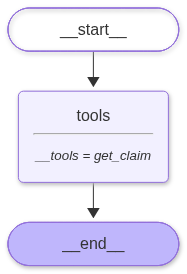

In [5]:
builder = StateGraph(
    MessagesState,
    context_schema=InvestigationContext,
)

builder.add_node("tools", ToolNode([get_claim]))
builder.add_edge(START, "tools")
builder.add_edge("tools", END)

graph = builder.compile()
graph

In [6]:
fake_model_call = AIMessage(
    content="",
    tool_calls=[
        {
            "name": "get_claim",
            "args": {"claim_id": "C-1042"},
            "id": "call_001",
            "type": "tool_call",
        }
    ],
)

context = InvestigationContext(
    principal=alice,
    claims=claims,
    grants=grants,
)

result = graph.invoke(
    {"messages": [fake_model_call]},
    context=context,
)

print(result["messages"][-1].content)

{"tenant_id": "northstar", "claim_id": "C-1042", "customer_id": "CUS-100", "status": "open", "loss_type": "water damage", "amount_usd": "4200"}


In [7]:
result["messages"]

[AIMessage(content='', additional_kwargs={}, response_metadata={}, id='7b129abc-9509-4bc9-888c-60f8fecbf96a', tool_calls=[{'name': 'get_claim', 'args': {'claim_id': 'C-1042'}, 'id': 'call_001', 'type': 'tool_call'}], invalid_tool_calls=[]),
 ToolMessage(content='{"tenant_id": "northstar", "claim_id": "C-1042", "customer_id": "CUS-100", "status": "open", "loss_type": "water damage", "amount_usd": "4200"}', name='get_claim', id='fefe31d4-ff91-45b1-844b-27f3819b6752', tool_call_id='call_001')]

## Trying with Bob

In [9]:
context = InvestigationContext(
    principal=bob,
    claims=claims,
    grants=grants,
)

try:
    result = graph.invoke(
        {"messages": [fake_model_call]},
        context=context,
    )
except Exception as e:
    print(f"Error: {e}")
else:
    print(result["messages"][-1].content)

Error: Access denied


The model does not need to know the employee's identity to invoke a business tool. Framework supplies the application-owned context during execution.

What it does not yet prove is that the context came from cryptographically verified credentials or that a malicious caller cannot bypass our in-process gateway.